# 🚀 Модуль 1. Урок 1. Основы Excel: архитектура таблиц, форматирование и культура формул

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_01_excel/lesson_01_interface_basics_formatting.ipynb)

## 📌 Бизнес-контекст и методология
Excel / Google Sheets остаются основным языком финансового моделирования и оперативной коммуникации в бизнесе.
Главный грех неопытного аналитика — создание «визуальной каши» (неоновые цвета, объединение ячеек `Merge & Center`, жестко зашитые константы в формулах).
Профессиональный финансовый отчет строится по принципам Foundation Design System: нейтральная сетка, сдержанные акценты, явное разделение входящих параметров (Inputs) и расчетных формул (Calculations).

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Моделирование SaaS P&L отчета
Построим отчет о прибылях и убытках (P&L) SaaS компании с расчетом валовой маржи и EBITDA.

In [2]:
# Демонстрация: Моделирование P&L структуры в Pandas (аналог Excel)
pnl_data = pd.DataFrame({
    'Статья P&L': ['1. Выручка (ARR)', '2. Себестоимость (COGS)', '3. Валовая прибыль (Gross Profit)', '4. Расходы на маркетинг (CAC)', '5. Расходы на R&D (Разработка)', '6. Операционная прибыль (EBITDA)'],
    'Q1 ($k)': [1000, -250, 750, -350, -200, 200],
    'Q2 ($k)': [1200, -280, 920, -390, -220, 310],
    'Q3 ($k)': [1450, -320, 1130, -440, -240, 450],
    'Q4 ($k)': [1750, -360, 1390, -500, -260, 630]
})
display(pnl_data)

,Статья P&L,Q1 ($k),Q2 ($k),Q3 ($k),Q4 ($k)
0,1. Выручка (ARR),1000,1200,1450,1750
1,2. Себестоимость (COGS),-250,-280,-320,-360
2,3. Валовая прибыль (Gross Profit),750,920,1130,1390
3,4. Расходы на маркетинг (CAC),-350,-390,-440,-500
4,5. Расходы на R&D (Разработка),-200,-220,-240,-260
5,6. Операционная прибыль (EBITDA),200,310,450,630


## 📊 Визуализация бизнес-кейса: Динамика маржинальности P&L
Построим динамику роста выручки и расширения EBITDA маржи по кварталам.

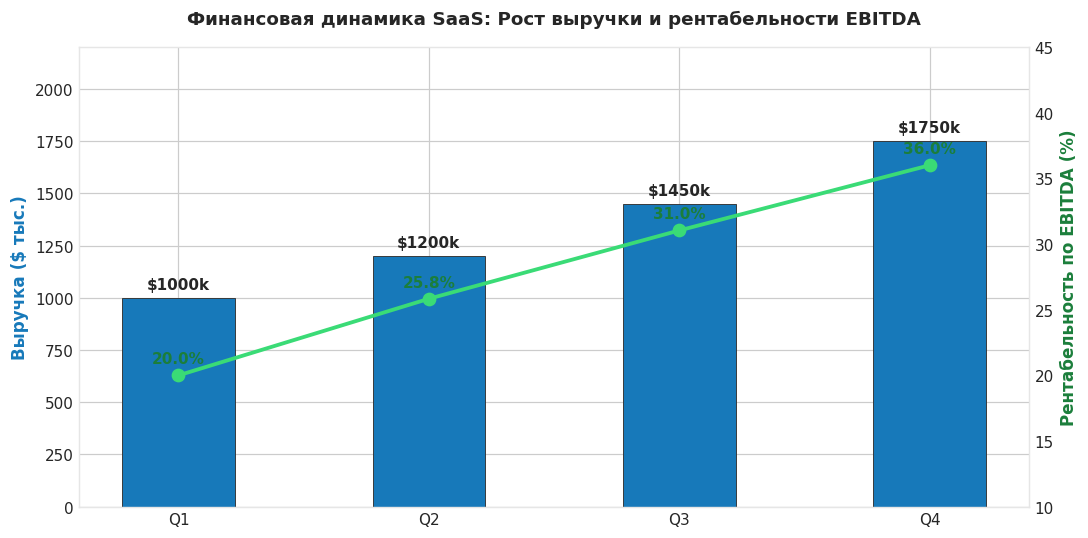

In [3]:
# Построение 2-осевого финансового отчета
quarters = ['Q1', 'Q2', 'Q3', 'Q4']
revenue = [1000, 1200, 1450, 1750]
ebitda = [200, 310, 450, 630]
ebitda_margin = [e / r * 100 for e, r in zip(ebitda, revenue)]

fig, ax1 = plt.subplots(figsize=(10, 5), dpi=110)

bars = ax1.bar(quarters, revenue, color=PRIMARY, width=0.45, label='Выручка ($k)', edgecolor='#333333', linewidth=0.6)
ax1.set_ylabel("Выручка ($ тыс.)", color=PRIMARY, fontsize=11, fontweight='bold')
ax1.set_ylim(0, 2200)

for b in bars:
    h = b.get_height()
    ax1.annotate(f"${h}k", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 4),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2 = ax1.twinx()
line = ax2.plot(quarters, ebitda_margin, color=SUCCESS, marker='o', linewidth=2.5, markersize=8, label='EBITDA Margin %')
ax2.set_ylabel("Рентабельность по EBITDA (%)", color='#1b7e3b', fontsize=11, fontweight='bold')
ax2.set_ylim(10, 45)
ax2.grid(False)

for i, txt in enumerate(ebitda_margin):
    ax2.annotate(f"{txt:.1f}%", (quarters[i], txt), textcoords="offset points", xytext=(0, 8), 
                 ha='center', fontweight='bold', color='#1b7e3b', fontsize=10)

ax1.set_title("Финансовая динамика SaaS: Рост выручки и рентабельности EBITDA", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет совокупного годового ARR
Найдите сумму выручки за все 4 квартала в `pnl_data`.

In [4]:
### ВАШ КОД ЗДЕСЬ
total_annual_revenue = sum(revenue)
print(f"Совокупная годовая выручка: ${total_annual_revenue:,.0f}k")

assert total_annual_revenue == 5400, "Годовая выручка должна быть равна 5400k"
print("✅ Тест успешно пройден: финансовые показатели сошлись!")

Совокупная годовая выручка: $5,400k
✅ Тест успешно пройден: финансовые показатели сошлись!


### 💡 Правило моделирования Fast
Финансовые аналитики следуют стандарту FAST: Flexible, Appropriate, Structured, Transparent. Никогда не объединяйте ячейки (Merge cells) — это ломает автоматические формулы и сортировку.